# Hyperparameter Testing
To assess which version of the autoencoder is the best, I will iteratively be changing the hyperameters and then use the "best" version (to be defined later what is best) and then move onto the next hyperparameter using that value

## Functions

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [3]:
# plotting function
def plot_training_curve(metrics_path):
    
    df = pd.read_csv(metrics_path)
    
    train_df = df[df["train_loss"].notna()]
    val_df = df[df["val_loss"].notna()]
    
    plt.figure(figsize=(6,4))
    
    plt.plot(train_df["epoch"], train_df["train_loss"], label="Train")
    plt.plot(val_df["epoch"], val_df["val_loss"], label="Validation")
    
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title("Autoencoder Training Curve")
    plt.legend()
    
    plt.show()
    
    best_val = val_df["val_loss"].min()
    best_epoch = val_df.loc[val_df["val_loss"].idxmin(), "epoch"]
    
    print("Best validation loss:", best_val)
    print("Best epoch:", best_epoch)
    
    return best_val

In [4]:
# convert embedding to images function
def embedding_to_image(df, feature):
    y = df["y"].astype(int)
    x = df["x"].astype(int)

    # shift coordinates so they start at zero
    y_rel = y - y.min()
    x_rel = x - x.min()

    height = int(y_rel.max()) + 1
    width = int(x_rel.max()) + 1

    img = np.zeros((height, width))

    img[y_rel, x_rel] = df[feature]

    return img


In [5]:
# visualize embedding images function
def plot_embedding_images(folder_path, num_features=4):
    
    files = glob.glob(f"{folder_path}/*.csv")
    
    for file in files:
        
        df = pd.read_csv(file)
        print("Image:", file.split("/")[-1])
        plt.figure(figsize=(12,3))
        
        for i in range(num_features):
            
            plt.subplot(1, num_features, i+1)
            
            img = embedding_to_image(df, f"ae{i}")
            
            plt.imshow(img)
            plt.title(f"ae{i}")
            plt.axis("off")
        
        plt.show()

In [6]:
# orignal image plotting
def plot_original_images(folder):

    files = glob.glob(f"{folder}/*.npz")

    for fp in files:

        data = np.load(fp)
        key = list(data.files)[0]
        arr = data[key]

        y = arr[:,0].astype(int)
        x = arr[:,1].astype(int)

        # first feature channel
        feature = arr[:,2]

        # shift coordinates
        y_rel = y - y.min()
        x_rel = x - x.min()

        height = int(y_rel.max()) + 1
        width = int(x_rel.max()) + 1

        img = np.zeros((height,width))

        img[y_rel, x_rel] = feature

        plt.figure(figsize=(5,5))
        plt.imshow(img)
        plt.title(fp.split("/")[-1])
        plt.colorbar()
        plt.show()

In [7]:
# labeled cloud plotting function
def plot_cloud_mask(folder):

    files = glob.glob(f"{folder}/*.npz")

    for fp in files:

        data = np.load(fp)
        key = list(data.files)[0]
        arr = data[key]

        y = arr[:,0].astype(int)
        x = arr[:,1].astype(int)

        label = arr[:,-1]   # last column
        
        # shift coordinates
        y_rel = y - y.min()
        x_rel = x - x.min()

        height = int(y_rel.max()) + 1
        width = int(x_rel.max()) + 1

        img = np.zeros((height,width))
        img[y_rel, x_rel] = label

        plt.figure(figsize=(4,4))
        plt.imshow(img, cmap="coolwarm")
        plt.title("Cloud Label: " + fp.split("/")[-1])
        plt.colorbar()
        plt.show()

In [8]:
# embeddings to cloud labels function
def compare_embeddings(embedding_csv, labeled_npz):

    # load embeddings
    emb = pd.read_csv(embedding_csv)

    # load labeled data
    data = np.load(labeled_npz)
    key = list(data.files)[0]
    arr = data[key]

    labels_df = pd.DataFrame({
        "y": arr[:,0].astype(int),
        "x": arr[:,1].astype(int),
        "label": arr[:,-1]
    })

    # merge on coordinates
    merged = emb.merge(labels_df, on=["y","x"], how="inner")

    print("Merged rows:", len(merged))

    cloud = merged[merged["label"] == 1]
    noncloud = merged[merged["label"] == -1]

    for i in range(4):

        plt.figure(figsize=(5,3))

        plt.hist(cloud[f"ae{i}"], bins=50, alpha=0.5, label="cloud")
        plt.hist(noncloud[f"ae{i}"], bins=50, alpha=0.5, label="non-cloud")

        plt.title(f"Embedding ae{i}")
        plt.legend()

        plt.show()

In [9]:
# auc curve function
def embedding_auc(embedding_csv, labeled_npz):

    emb = pd.read_csv(embedding_csv)

    data = np.load(labeled_npz)
    key = list(data.files)[0]
    arr = data[key]

    labels_df = pd.DataFrame({
        "y": arr[:,0].astype(int),
        "x": arr[:,1].astype(int),
        "label": arr[:,-1]
    })

    merged = emb.merge(labels_df, on=["y","x"], how="inner")

    # remove uncertain pixels if present
    merged = merged[merged["label"] != 0]

    features = [c for c in merged.columns if "ae" in c]

    X = merged[features]
    y = (merged["label"] == 1).astype(int)

    model = LogisticRegression(max_iter=1000)
    model.fit(X, y)

    probs = model.predict_proba(X)[:,1]

    auc = roc_auc_score(y, probs)

    return auc

### Original Images


In [10]:
images = [
"O013257",
"O013490",
"O012791"
]

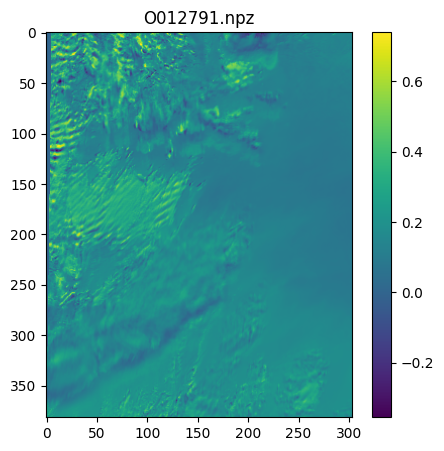

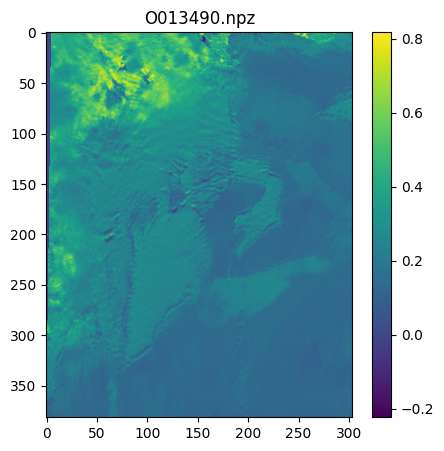

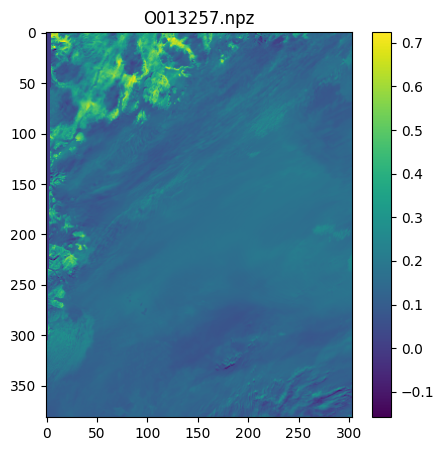

In [11]:
plot_original_images("../data/labeled_images")


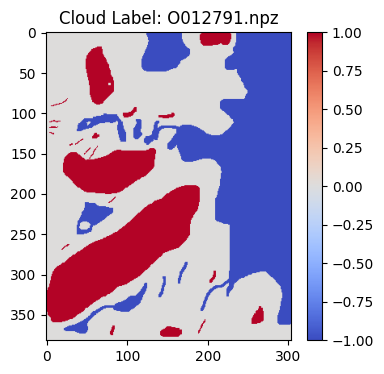

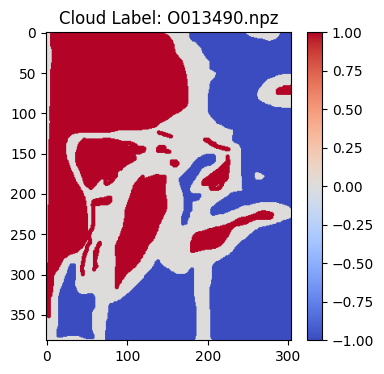

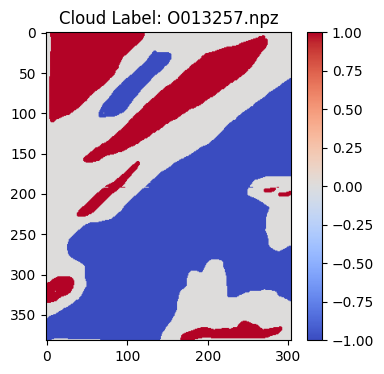

In [12]:
plot_cloud_mask("../data/labeled_images")

### Baseline model
The baseline model we will test against will use:
- 25 images
- 30 epochs
- embedding = 8
- learning rate = 0.001
- channels 16-32
- activation function ReLU

This check point is called: baseline-epoch
Lightning Log: version_17
Image names: {number}_base.csv

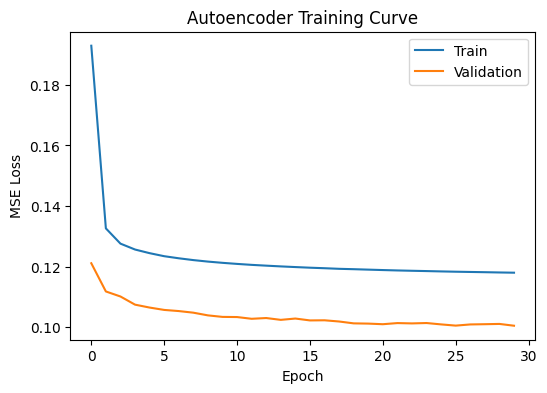

Best validation loss: 0.1004430949687957
Best epoch: 29


np.float64(0.1004430949687957)

In [13]:
plot_training_curve("lightning_logs/version_17/metrics.csv")

Image: O012791_base.csv


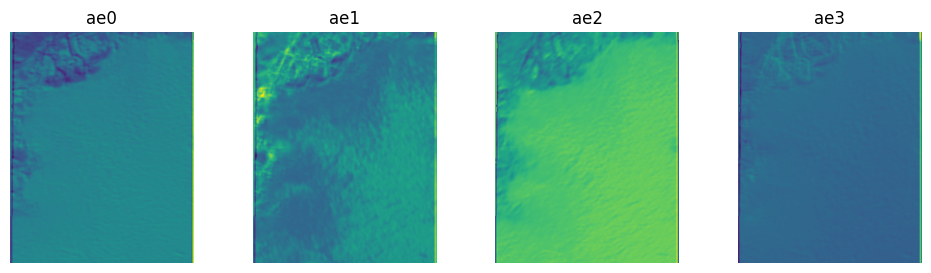

Image: O013257_base.csv


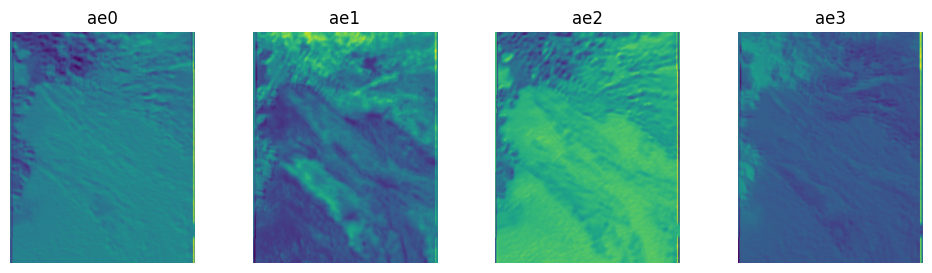

Image: O013490_base.csv


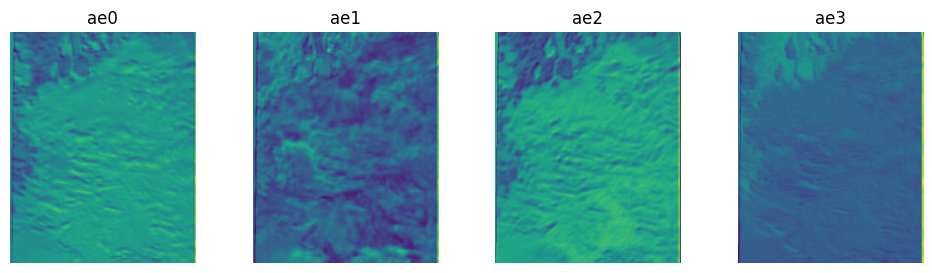

In [14]:
plot_embedding_images("../data/hyperparam_images/base")

Merged rows: 114955


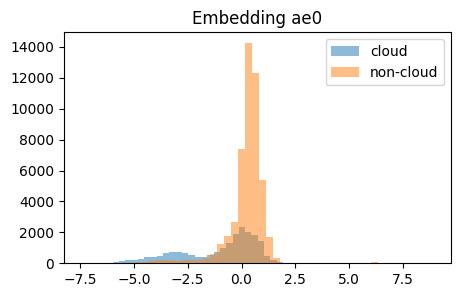

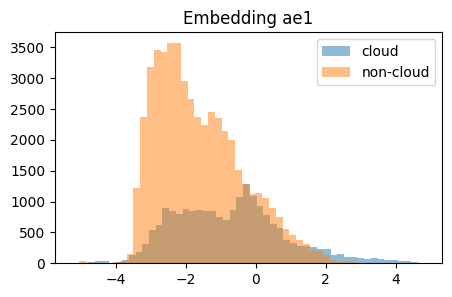

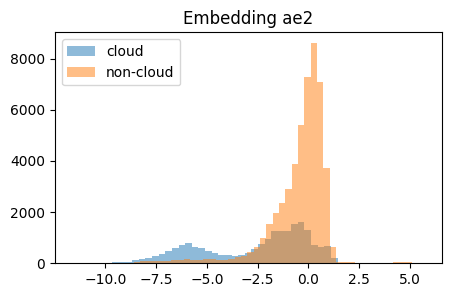

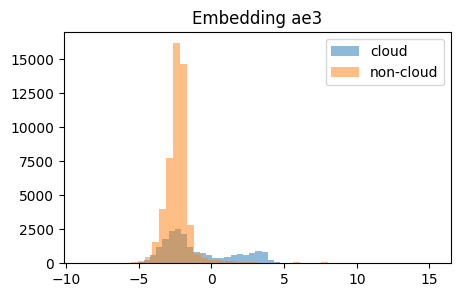

In [15]:
compare_embeddings(
    "../data/hyperparam_images/base/O013257_base.csv",
    "../data/labeled_images/O013257.npz"
)

In [16]:
total = 0
for img in images:
    auc = embedding_auc(
        f"../data/hyperparam_images/base/{img}_base.csv",
        f"../data/labeled_images/{img}.npz"
    )
    print(img, auc)
    total = total + auc
print(total/3)

O013257 0.8005441288477871
O013490 0.8247648218296049
O012791 0.7893372975781143
0.8048820827518354


### Embeddings Size comparison

up the embedding size from 16 to 32

This check point is called:hyp-emb16-epoch
Lightning Log: version_18
Image names: {number}_em16.csv

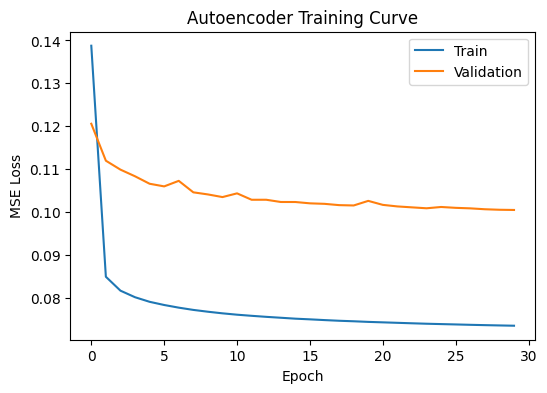

Best validation loss: 0.1004630252718925
Best epoch: 29


np.float64(0.1004630252718925)

In [17]:
plot_training_curve("lightning_logs/version_18/metrics.csv")

The training loss decreases significantly below the validation loss, indicating the model may be fitting patterns specific to the training images rather than learning representations that generalize across images. This effect is more pronounced with larger latent dimensions, which increase the model’s capacity and may allow it to memorize training patterns rather than learning generalizable cloud features.

Image: O013257_em16.csv


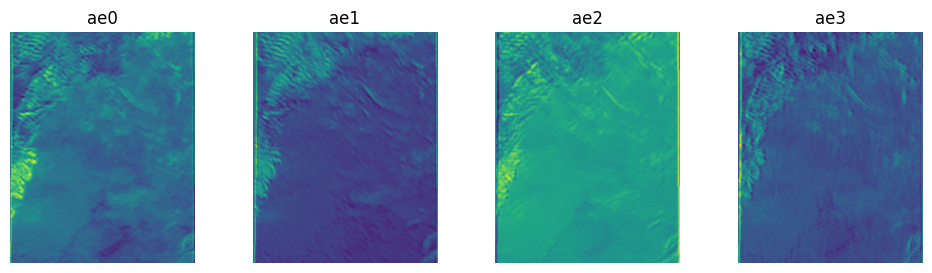

Image: O013490_em16.csv


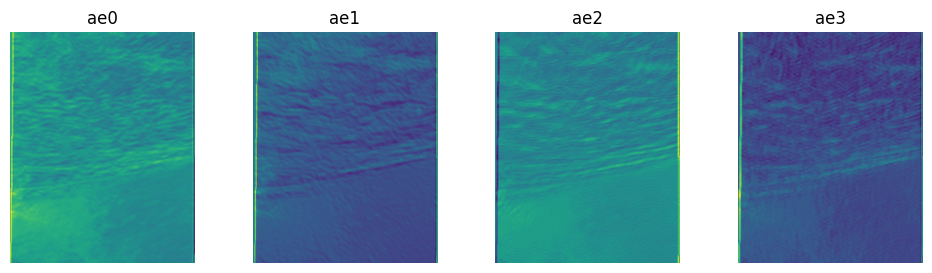

Image: O012791_em16.csv


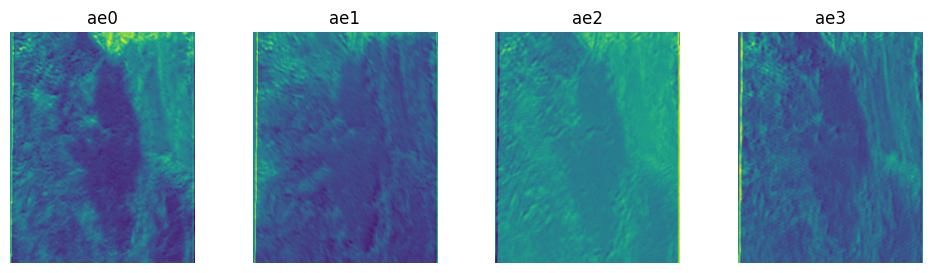

In [18]:
plot_embedding_images("../data/hyperparam_images/em16")

Merged rows: 114310


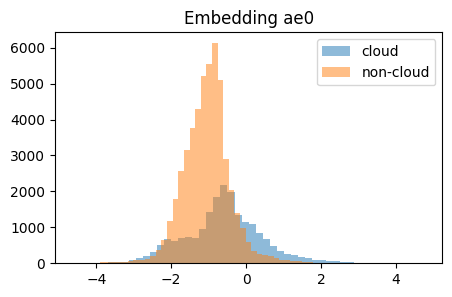

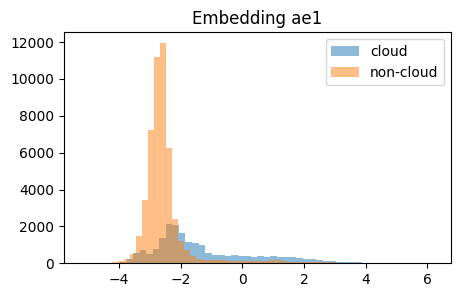

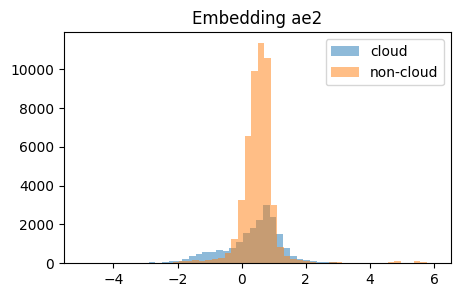

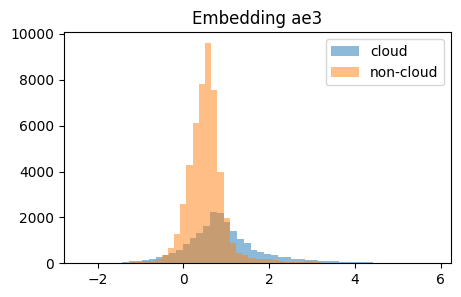

In [19]:
compare_embeddings(
    "../data/hyperparam_images/em16/O013257_em16.csv",
    "../data/labeled_images/O013257.npz"
)

In [20]:
total = 0
for img in images:

    auc = embedding_auc(
        f"../data/hyperparam_images/em16/{img}_em16.csv",
        f"../data/labeled_images/{img}.npz"
    )
    print(img, auc)
    total = total + auc

print(total/3)

O013257 0.8748256565014499
O013490 0.8581431898181615
O012791 0.8586941479647326
0.8638876647614481


Base line model had this so all AUC values went up
- O013257: 0.800544128847787
- O013490: 0.824764821829604
- O012791: 0.789337297578114

Because of this, we will continue with 16 embeddings in our next tuning

## learning rate

changing learning size to .0001

This check point is called:hyp-lr_e4-epoch
Lightning Log: version_19
Image names: {number}_lre4.csv

changing learning size to 0.005

This check point is called:hyp-lr_5e3-epoch
Lightning Log: version_20
Image names: {number}_lr5e3.csv




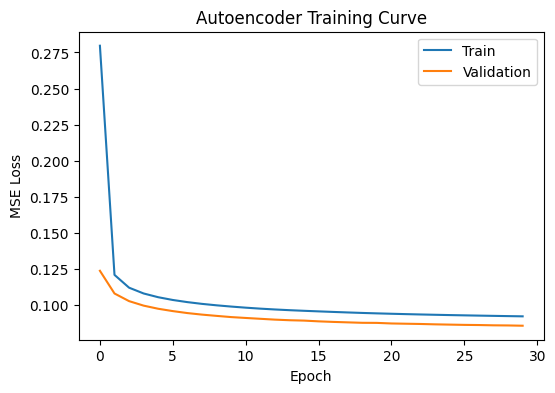

Best validation loss: 0.0852927193045616
Best epoch: 29


np.float64(0.0852927193045616)

In [21]:
plot_training_curve("lightning_logs/version_19/metrics.csv")

Image: O013490_lre4.csv


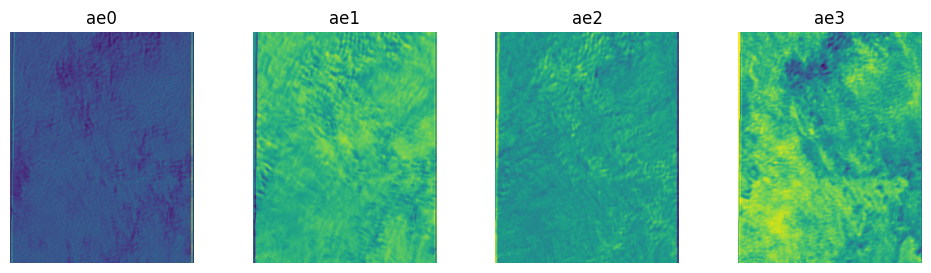

Image: O013257_lre4.csv


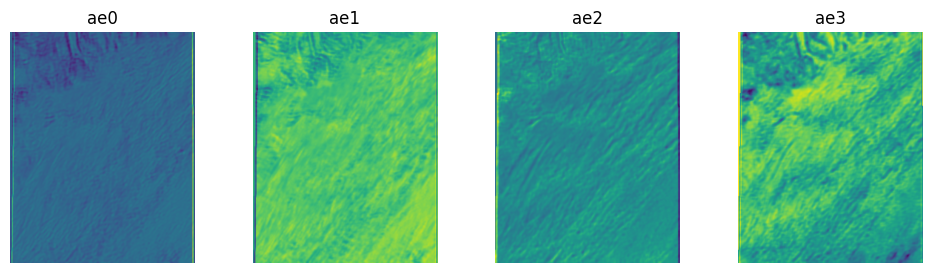

Image: O012791_lre4.csv


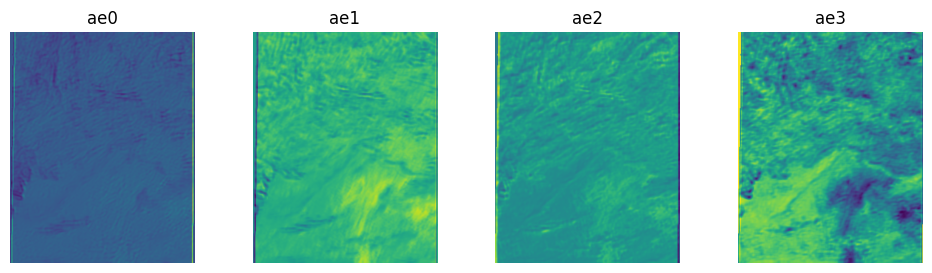

In [22]:
plot_embedding_images("../data/hyperparam_images/lr_e4")

Merged rows: 114886


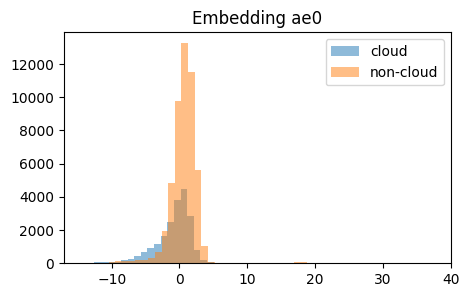

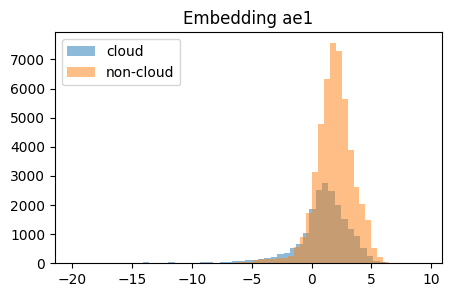

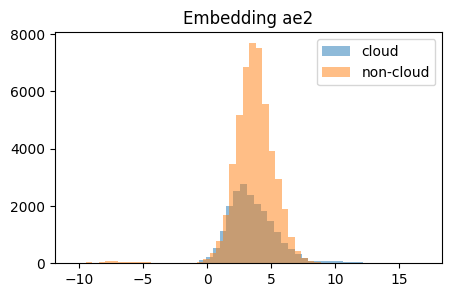

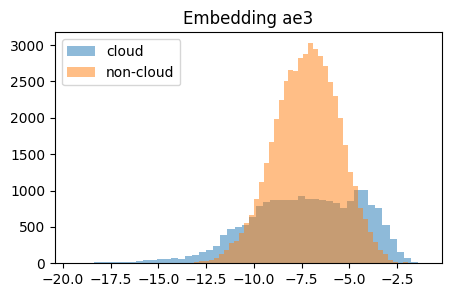

In [23]:
compare_embeddings(
    "../data/hyperparam_images/lr_e4/O013257_lre4.csv",
    "../data/labeled_images/O013257.npz"
)

In [34]:
total = 0
for img in images:
    auc = embedding_auc(
        f"../data/hyperparam_images/lr_e4/{img}_lre4.csv",
        f"../data/labeled_images/{img}.npz"
    )
    print(img, auc)
    total = total + auc
print(total/3)

O013257 0.8224603327316955
O013490 0.7304911862703986
O012791 0.8586001631439163
0.8038505607153367


These AUC values are lower than previous learning rate

In [25]:
total = 0
for img in images:

    auc = embedding_auc(
        f"../data/hyperparam_images/lr_5e3/{img}_lr5e3.csv",
        f"../data/labeled_images/{img}.npz"
    )
    print(img, auc)
    total = total + auc
print(total/3)

O013257 0.868142448489712
O013490 0.9158512220179283
O012791 0.7276660759458866
0.8372199154845089


In [26]:
total/3

0.8372199154845089

avg of before: 0.8638876647614481 so this is lower because it was really good on the second one but really bad on the third

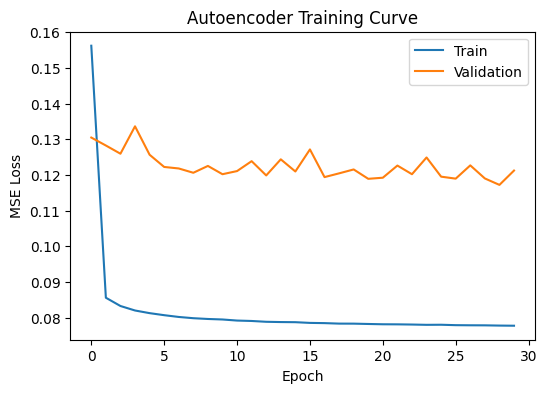

Best validation loss: 0.1172014847397804
Best epoch: 28


np.float64(0.1172014847397804)

In [27]:
plot_training_curve("lightning_logs/version_20/metrics.csv")

### changing channels
baseline 8 - 16 - 32

try: 

8 to 32 to 64
This check point is called:hyp-ch_med-epoch
Lightning Log: version_21
Image names: {number}_med.csv

8 to 64 to 128
This check point is called:hyp-ch_lg-epoch
Lightning Log: version_22
Image names: {number}_lg.csv



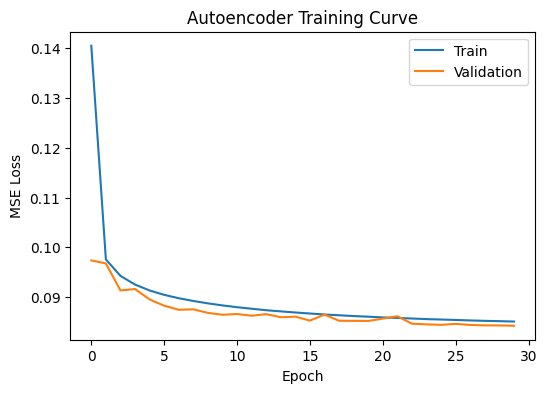

Best validation loss: 0.0842681527137756
Best epoch: 29


np.float64(0.0842681527137756)

In [28]:
plot_training_curve("lightning_logs/version_21/metrics.csv")

In [29]:
total = 0
for img in images:

    auc = embedding_auc(
        f"../data/hyperparam_images/ch_med/{img}_med.csv",
        f"../data/labeled_images/{img}.npz"
    )
    print(img, auc)
    total = total + auc
print(total/3)

O013257 0.8338742416979408
O013490 0.8866666380364252
O012791 0.8245288683360499
0.8483565826901387


still smaller than 0.86388

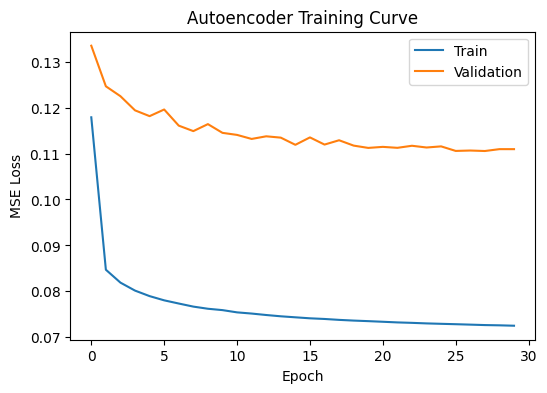

Best validation loss: 0.1105571240186691
Best epoch: 27


np.float64(0.1105571240186691)

In [30]:
plot_training_curve("lightning_logs/version_22/metrics.csv")

In [31]:
total = 0
for img in images:

    auc = embedding_auc(
        f"../data/hyperparam_images/ch_lg/{img}_mlg.csv",
        f"../data/labeled_images/{img}.npz"
    )
    print(img, auc)
    total = total + auc
print(total/3)

O013257 0.8406771816369911
O013490 0.8562592295369961
O012791 0.6931704601107691
0.7967022904282522


still worse so keeping original 16 and 32 layers

### changing activation function
ReLU to LeakyReLU

This check point is called:hyp-af-epoch (activation function)
Lightning Log: version_23
Image names: {number}_leaky.csv

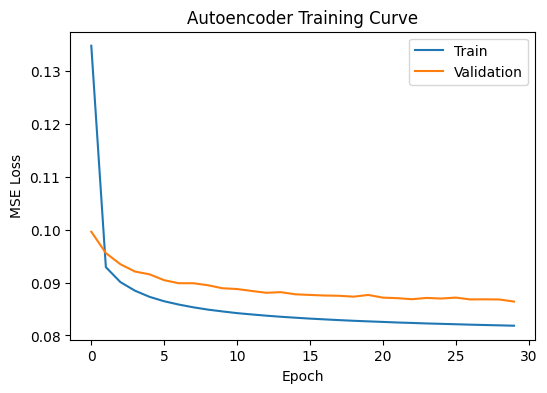

Best validation loss: 0.0863987207412719
Best epoch: 29


np.float64(0.0863987207412719)

In [32]:
plot_training_curve("lightning_logs/version_23/metrics.csv")

In [33]:
total = 0
for img in images:

    auc = embedding_auc(
        f"../data/hyperparam_images/leaky/{img}_leaky.csv",
        f"../data/labeled_images/{img}.npz"
    )
    print(img, auc)
    total = total + auc
print(total/3)

O013257 0.7775015489447324
O013490 0.8857362517486629
O012791 0.6659356687953462
0.776391156496247


made it worse again